In [6]:
import meep as mp
import numpy as np
import matplotlib.pyplot as plt
import argparse
def main(args):

    resolution = 40                       # pixels/um

    a_start = args.a_start                # starting periodicity
    a_end = args.a_end                    # ending periodicity
    s_cav = args.s_cav                    # cavity length
    r = args.r                            # hole radius  (units of a)
    h = args.hh                           # waveguide height
    w = args.w                            # waveguide width

    dair = 1.00                           # air padding
    dpml = 1.00                           # PML thickness

    Ndef = args.Ndef                      # number of defect periods
    a_taper = mp.interpolate(Ndef, [a_start,a_end])
    dgap = a_end-2*r*a_end

    Nwvg = args.Nwvg                      # number of waveguide periods
    sx = 2*(Nwvg*a_start+sum(a_taper))-dgap+s_cav
    sy = dpml+dair+w+dair+dpml
    sz = dpml+dair+h+dair+dpml

    cell_size = mp.Vector3(sx,sy,sz)
    boundary_layers = [mp.PML(dpml)]

    nSi = 3.45
    Si = mp.Medium(index=nSi)

    geometry = [mp.Block(material=Si, center=mp.Vector3(), size=mp.Vector3(mp.inf,w,h))]

    for mm in range(Nwvg):
        geometry.append(mp.Cylinder(material=mp.air, radius=r*a_start, height=mp.inf,
                                    center=mp.Vector3(-0.5*sx+0.5*a_start+mm*a_start,0,0)))
        geometry.append(mp.Cylinder(material=mp.air, radius=r*a_start, height=mp.inf,
                                    center=mp.Vector3(+0.5*sx-0.5*a_start-mm*a_start,0,0)))

    for mm in range(Ndef+2):
        geometry.append(mp.Cylinder(material=mp.air, radius=r*a_taper[mm], height=mp.inf,
                                    center=mp.Vector3(-0.5*sx+Nwvg*a_start+(sum(a_taper[:mm]) if mm>0 else 0)+0.5*a_taper[mm],0,0)))
        geometry.append(mp.Cylinder(material=mp.air, radius=r*a_taper[mm], height=mp.inf,
                                    center=mp.Vector3(+0.5*sx-Nwvg*a_start-(sum(a_taper[:mm]) if mm>0 else 0)-0.5*a_taper[mm],0,0)))

    lambda_min = 1.46        # minimum source wavelength
    lambda_max = 1.66        # maximum source wavelength
    fmin = 1/lambda_max
    fmax = 1/lambda_min
    fcen = 0.5*(fmin+fmax)
    df = fmax-fmin

    sources = [mp.Source(mp.GaussianSource(fcen, fwidth=df), component=mp.Ey, center=mp.Vector3())]

    symmetries = [mp.Mirror(mp.X,+1), mp.Mirror(mp.Y,-1), mp.Mirror(mp.Z,+1)]

    sim = mp.Simulation(resolution=resolution,
                        cell_size=cell_size,
                        boundary_layers=boundary_layers,
                        geometry=geometry,
                        sources=sources,
                        dimensions=3,
                        symmetries=symmetries)

    sim.run(mp.in_volume(mp.Volume(center=mp.Vector3(), size=mp.Vector3(sx,sy,0)), mp.at_end(mp.output_epsilon, mp.output_efield_y)),
            mp.after_sources(mp.Harminv(mp.Ey, mp.Vector3(), fcen, df)),
            until_after_sources=500)
    
if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('-a_start', type=float, default=0.43, help='starting periodicity (default: 0.43 um)')
    parser.add_argument('-a_end', type=float, default=0.33, help='ending periodicity (default: 0.33 um)')
    parser.add_argument('-s_cav', type=float, default=0.146, help='cavity length (default: 0.146 um)')
    parser.add_argument('-r', type=float, default=0.28, help='hole radius (default: 0.28 um)')
    parser.add_argument('-hh', type=float, default=0.22, help='waveguide height (default: 0.22 um)')
    parser.add_argument('-w', type=float, default=0.50, help='waveguide width (default: 0.50 um)')
    parser.add_argument('-Ndef', type=int, default=3, help='number of defect periods (default: 3)')
    parser.add_argument('-Nwvg', type=int, default=8, help='number of waveguide periods (default: 8)')
    args, unknown = parser.parse_known_args()
    main(args)
    
print("Simulation completed!")

-----------
Initializing structure...
Padding x to even number of grid points.
Padding z to even number of grid points.
Halving computational cell along direction x
Halving computational cell along direction y
Halving computational cell along direction z
time for choose_chunkdivision = 0.00830889 s
Working in 3D dimensions.
Computational cell is 10.675 x 4.5 x 4.225 with resolution 40
     block, center = (0,0,0)
          size (1e+20,0.5,0.22)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.9025,11.9025,11.9025)
     cylinder, center = (-5.1254,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (5.1254,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder

, center = (-4.6954,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (4.6954,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (-4.2654,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (4.2654,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (-3.8354,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (3.8354,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant epsilon diagonal = (1,1,1)
     cylinder, center = (-3.4054,0,0)
          radius 0.1204, height 1e+20, axis (0, 0, 1)
          dielectric constant 

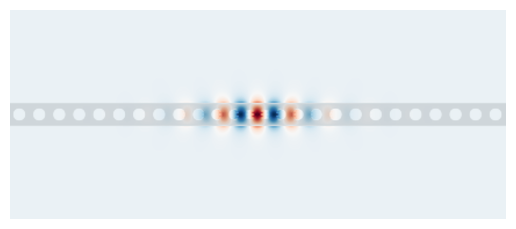

In [8]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

eps_h5file = h5py.File('eps-000621.19.h5','r')
eps_data = np.array(eps_h5file['eps'])
ey_h5file = h5py.File('ey-000621.19.h5','r')
ey_data = np.array(ey_h5file['ey'])
plt.figure(dpi=100)
plt.imshow(eps_data.transpose(), interpolation='spline36', cmap='binary')
plt.imshow(ey_data.transpose(), interpolation='spline36', cmap='RdBu', alpha=0.9)
plt.axis('off')
plt.show()